# 04 · Part 2: Did Hurricane Ian Lower Flood-Zone Home Values?

Hurricane Ian made landfall at Cayo Costa on **September 28, 2022** as a Category 4 storm, with a storm
surge of up to 15 feet on Fort Myers Beach and Sanibel. It was the costliest disaster in Florida's history.

**Question:** after Ian, did single-family homes in FEMA's high-risk flood zone sell for less, *relative to
comparable homes outside it*, than they did before the storm?

**Design: difference-in-differences (DiD).**

| | Before Ian (Jan 2019 – Sep 2022) | After Ian (Oct 2022 – Sep 2024) |
|---|---|---|
| **Treated:** in the high-risk zone (SFHA) on the **2008** flood map, the map in force when Ian hit | price gap A | price gap B |
| **Control:** outside it | | |

The estimate is **B − A**: the change in the flood-zone price gap. Anything that hit both groups (the 2022
mortgage-rate shock, the county-wide cycle) cancels out. The key assumption is **parallel trends**:
without Ian, the gap would have stayed where it was. Section 3 tests that as far as data allows.

**Main sample:** undamaged sales through **Sep 2024**, stopping before Hurricanes Helene and Milton. Damaged
sales and 2025 are robustness checks. Code: `src/did.py`.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import did as D
import hedonic as h
from plotting import *

warnings.filterwarnings("ignore")
use_style()
pd.set_option("display.width", 200)
FIG = ROOT / "figures"

d = D.load()
s = D.main_sample(d)
counts = s.groupby(["sfha", "post"]).size().unstack()
counts.index, counts.columns = ["control (outside SFHA)", "treated (in 2008 SFHA)"], ["before Ian", "after Ian"]
counts

,before Ian,after Ian
control (outside SFHA),38383,14533
treated (in 2008 SFHA),23000,7411


## 1. Building up the estimate

Start from the raw 2×2 comparison and add controls one step at a time. Watching the estimate move shows
what each control is doing.

In [2]:
def raw_did(df):
    g = df.groupby(["sfha", "post"])["log_price"].mean()
    v = (g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0])
    return 100 * (np.exp(v) - 1)

steps = {}
steps["Raw 2×2 (mean log price)"] = {"premium_pct": raw_did(s), "lo_pct": np.nan, "hi_pct": np.nan}
r, _ = D.estimate(s, ["did"], extra=["did"], controls=["sfha"], categorical=(), fe=pd.Series(0, index=s.index))
steps["+ sale-month fixed effects"] = r.iloc[0]
r, _ = D.estimate(s, ["did"], extra=["did"], fe=pd.Series(0, index=s.index))
steps["+ home features & waterfront type"] = r.iloc[0]
main, main_fit = D.did(s)
steps["+ block-group fixed effects  (MAIN)"] = main.iloc[0]
build = pd.DataFrame(steps).T[["premium_pct", "lo_pct", "hi_pct"]]
build.round(1)

,premium_pct,lo_pct,hi_pct
Raw 2×2 (mean log price),-11.4,NaN,NaN
+ sale-month fixed effects,-12.8,-17.7,-7.6
+ home features & waterfront type,-8.4,-11.2,-5.6
+ block-group fixed effects (MAIN),-5.8,-7.2,-4.5


- The **raw** comparison is misleading: flood-zone homes are bigger and on the water, and the mix of what
  sold changed after the storm.
- **Month fixed effects** remove the market cycle.
- **Home features** compare like with like.
- **Block-group fixed effects** compare homes only with neighbors in the same small area.

**Main estimate: flood-zone homes sold about 5.8% below what the pre-storm gap implies** (95% CI roughly
−7.2% to −4.5%). On the median pre-Ian flood-zone sale, that's the dollar figure below.

In [3]:
med = s.loc[(s["sfha"] == 1) & (s["post"] == 0), "sale_price"].median()
e = main.iloc[0]
print(f"Median pre-Ian flood-zone sale: ${med:,.0f}  ->  effect ≈ ${-med*e.premium_pct/100:,.0f} "
      f"(95% CI ${-med*e.hi_pct/100:,.0f} – ${-med*e.lo_pct/100:,.0f}) per home")

Median pre-Ian flood-zone sale: $393,400  ->  effect ≈ $22,911 (95% CI $17,515 – $28,231) per home


## 2. Timing: an event study

Instead of one before/after split, estimate the flood-zone gap in every six-month period relative to the
last six months before the storm (Apr–Sep 2022). If Ian caused the drop, the break should be at Ian, not before.

Joint test that all pre-Ian coefficients = 0:  p = 0.013


start,2018-10-01,2019-04-01,2019-10-01,2020-04-01,2020-10-01,2021-04-01,2021-10-01,2022-10-01,2023-04-01,2023-10-01,2024-04-01
premium_pct,0.7,-0.0,1.2,1.4,2.3,2.4,1.8,-7.7,-4.5,-2.4,-3.0
lo_pct,-2.2,-2.5,-1.3,-1.1,0.4,0.9,0.3,-10.1,-6.4,-4.3,-4.8
hi_pct,3.7,2.5,3.8,3.8,4.3,3.9,3.4,-5.3,-2.5,-0.4,-1.2


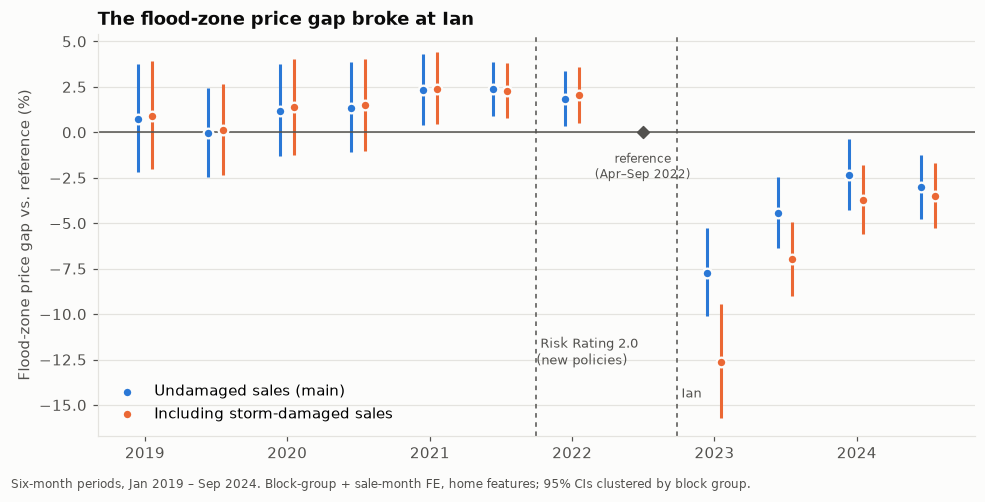

In [4]:
es_u, pre_p = D.event_study(s)
es_d, _ = D.event_study(D.main_sample(d, damaged=True))

fig, ax = plt.subplots(figsize=(9, 4.4))
for es, label, color, dx in [(es_u, "Undamaged sales (main)", C1, -18), (es_d, "Including storm-damaged sales", C2, 18)]:
    x = es["start"] + pd.Timedelta(days=91 + dx)
    ax.vlines(x, es["lo_pct"], es["hi_pct"], color=color, lw=2)
    ax.scatter(x, es["premium_pct"], color=color, s=40, zorder=3, edgecolor=SURFACE, lw=1.5, label=label)
ax.scatter([pd.Timestamp("2022-07-01")], [0], marker="D", s=30, color=INK2, zorder=3)
ax.annotate("reference\n(Apr–Sep 2022)", (pd.Timestamp("2022-07-01"), 0), xytext=(0, -30),
            textcoords="offset points", ha="center", fontsize=8, color=INK2)
ax.axhline(0, color=INK2, lw=1)
event(ax, "2022-09-28", "Ian", y=0.12)
event(ax, "2021-10-01", "Risk Rating 2.0\n(new policies)", y=0.25)
ax.set_ylabel("Flood-zone price gap vs. reference (%)")
ax.set_title("The flood-zone price gap broke at Ian")
ax.legend(loc="lower left"); year_axis(ax)
source_note(fig, "Six-month periods, Jan 2019 – Sep 2024. Block-group + sale-month FE, home features; 95% CIs clustered by block group.")
save(fig, FIG / "04_event_study.png")
print(f"Joint test that all pre-Ian coefficients = 0:  p = {pre_p:.3f}")
es_u.set_index("start")[["premium_pct", "lo_pct", "hi_pct"]].round(1).T

**Read:**
- The sharpest move in the whole series is **right at Ian**: −7.7% in the first six months after landfall,
  then partial recovery to about −2.5 to −4.5%.
- **The pre-period isn't perfectly flat.** A joint test rejects "all pre-Ian gaps = 0" (p ≈ 0.01).
  The pattern is a modest **+1 to +2.4%** flood-zone premium in 2020–21 that **faded in the six months before
  Ian**. Two candidate explanations, neither provable here:
  1. the pandemic **waterfront boom** in 2020–21 pushed water-adjacent homes up, then cooled as rates rose;
  2. **FEMA's Risk Rating 2.0** repriced flood insurance by property-level risk for new policies from Oct 2021
     and for renewals from Apr 2022, raising costs for many high-risk homes just before the storm.

Either way, parallel trends holds only approximately. Section 3 checks how much that matters.

## 3. Robustness: does the answer depend on the choices made?

In [5]:
WF = D.WATERFRONT
specs = {}
specs["Main: undamaged, Jan 2019 – Sep 2024"] = main.iloc[0]

r, _ = D.did(D.main_sample(d, damaged=True)); specs["Include storm-damaged sales"] = r.iloc[0]

s2 = s.copy()
for w in WF[1:]:
    s2[f"wfpost_{w}"] = (s2["waterfront"] == w) * s2["post"]
wfp = [f"wfpost_{w}" for w in WF[1:]]
r, _ = D.estimate(s2, ["did"], extra=["did"] + wfp); specs["+ waterfront type × post (water lost value, not risk?)"] = r.iloc[0]

s3 = s.assign(sfha_trend=s["sfha"] * s["t"])
r, _ = D.estimate(s3, ["did"], extra=["did", "sfha_trend"]); specs["+ flood-zone-specific linear trend"] = r.iloc[0]

r, _ = D.estimate(s2, ["did"], extra=["did"] + wfp, fe=s2["block_group"] + "_" + s2["post"].astype(str))
specs["+ block group × post FE (edge-of-zone homes only)"] = r.iloc[0]

r, _ = D.did(D.main_sample(d, end="2026-01-01")); specs["Extend window through Dec 2025"] = r.iloc[0]

rs = s[s.groupby("parcel_id")["post"].transform("nunique") == 2]
r, _ = D.estimate(rs, ["did"], extra=["did"], controls=[], categorical=(), fe=rs["parcel_id"])
specs[f"Repeat sales: same home before & after ({rs['parcel_id'].nunique():,} homes)"] = r.iloc[0]

pl = s[s["sale_date"] < "2022-07-01"].copy()
pl["post"] = (pl["sale_date"] >= "2020-10-01").astype(float); pl["did"] = pl["sfha"] * pl["post"]
r, _ = D.did(pl); specs["PLACEBO: fake storm Oct 2020, pre-Ian data only"] = r.iloc[0]

rob = pd.DataFrame(specs).T[["premium_pct", "lo_pct", "hi_pct", "n"]]
rob.round(1)

,premium_pct,lo_pct,hi_pct,n
"Main: undamaged, Jan 2019 – Sep 2024",-5.8,-7.2,-4.5,83327.0
Include storm-damaged sales,-8.2,-9.8,-6.6,85974.0
"+ waterfront type × post (water lost value, not risk?)",-5.2,-6.6,-3.8,83327.0
+ flood-zone-specific linear trend,-7.3,-9.3,-5.1,83327.0
+ block group × post FE (edge-of-zone homes only),-2.0,-4.1,0.0,83327.0
Extend window through Dec 2025,-5.8,-7.1,-4.5,97248.0
"Repeat sales: same home before & after (4,776 homes)",-4.4,-5.7,-3.0,10244.0
"PLACEBO: fake storm Oct 2020, pre-Ian data only",1.5,-0.3,3.2,58480.0


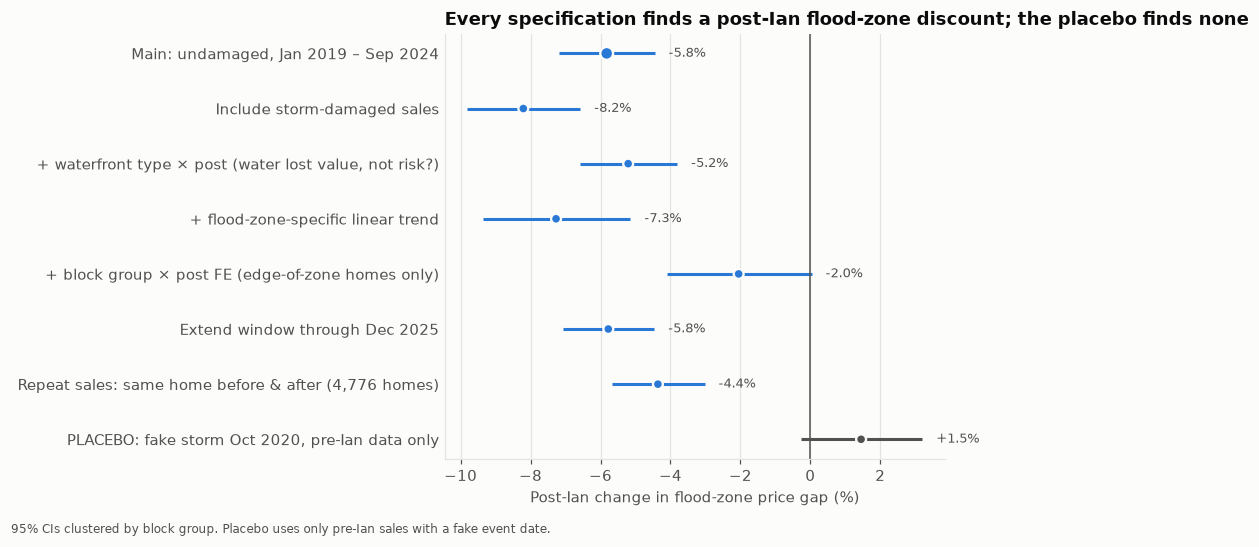

In [6]:
p = rob.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(p))
is_placebo = p.index.str.startswith("PLACEBO")
is_main = p.index.str.startswith("Main")
colors = np.where(is_placebo, INK2, C1)
ax.hlines(y, p["lo_pct"], p["hi_pct"], color=colors, lw=2)
ax.scatter(p["premium_pct"], y, color=colors, s=np.where(is_main, 70, 42), zorder=3, edgecolor=SURFACE, lw=1.5)
for i, v in enumerate(p["premium_pct"]):
    ax.text(p["hi_pct"].iloc[i] + 0.4, i, f"{v:+.1f}%", va="center", fontsize=8.5, color=INK2)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(y, p.index); ax.tick_params(axis="y", length=0)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Post-Ian change in flood-zone price gap (%)")
ax.set_title("Every specification finds a post-Ian flood-zone discount; the placebo finds none")
source_note(fig, "95% CIs clustered by block group. Placebo uses only pre-Ian sales with a fake event date.")
save(fig, FIG / "04_robustness.png")

In [7]:
# Sensitivity to the pre-trend: how big a post-Ian trend violation would erase the result?
pre = es_u.loc[es_u["period"] < 0, "premium_pct"]
M = pre.abs().max()
e = main.iloc[0]
print(f"Largest pre-Ian deviation from the reference period: {M:.1f} points")
print(f"Main estimate {e.premium_pct:.1f}%; if the post-Ian period were off-trend by as much as {M:.1f} points "
      f"in the flood zone's favor, the effect would still be {e.premium_pct + M:.1f}% "
      f"(upper CI {e.hi_pct + M:.1f}%).")

Largest pre-Ian deviation from the reference period: 2.4 points
Main estimate -5.8%; if the post-Ian period were off-trend by as much as 2.4 points in the flood zone's favor, the effect would still be -3.4% (upper CI -2.1%).


**Read:**
- **The direction never changes.** Every specification finds flood-zone homes lost relative value after Ian.
  The placebo (a fake "storm" in Oct 2020) is small and not significant.
- **Size range: about 2% to 8%.**
  - Including damaged homes gives a larger effect, as expected.
  - A flood-zone-specific trend gives a larger one too: the pre-Ian fade means the "before" gap was
    already shrinking, and extrapolating that gives a bigger break.
  - **Repeat sales** (the same house sold before and after, so nothing about the house itself can differ)
    gives −4.4%.
  - The smallest estimate is **block group × post FE**, which compares flood-zone homes only with
    non-flood-zone homes in the *same* block group *in the same period*. That isolates homes near the zone
    boundary, the lowest-risk part of the flood zone. Section 4 shows that's where the effect is smallest.
- **Pre-trend sensitivity:** even assuming a post-Ian trend violation as large as the worst pre-period
  deviation, the effect stays clearly negative.
- **Waterfront × post** barely moves the estimate: it isn't just that *waterfront* lost appeal, it's *flood risk*.

## 4. Mechanisms: where was the discount largest?

If the discount reflects **flood risk**, it should grow with risk (a dose-response), and depend on actual
exposure rather than only on the map label.

In [8]:
mech = {}
ss = s.copy()
# (a) zone type: VE = coastal high-hazard (wave action) vs AE / A (still-water flooding)
for z in ["AE", "VE", "A"]:
    ss[f"z_{z}"] = (ss["flood_zone_2008"] == z) * ss["post"]
r, _ = D.estimate(ss, ["z_AE", "z_VE"], extra=["z_AE", "z_VE", "z_A"])
mech["Zone AE (still-water flood risk)"] = r.loc["z_AE"]
mech["Zone VE (coastal wave hazard)"] = r.loc["z_VE"]

# (b) how much of the surrounding block group is in the flood zone
bins = pd.cut(ss["bg_sfha_share"], [-.01, .5, .9, 1.0], labels=["<50%", "50–90%", "90–100%"])
names = []
for b in bins.cat.categories:
    names.append(f"share_{b}"); ss[names[-1]] = ss["did"] * (bins == b)
r, _ = D.estimate(ss, names, extra=names)
for b, n in zip(bins.cat.categories, names):
    mech[f"Flood-zone home in a block group {b} flood zone"] = r.loc[n]

# (c) Nov 2022 remap: label vs. underlying risk. Groups by (2008 map, current map) status
ss["remap"] = ss["sfha_2008"].map({True: "in", False: "out"}) + "→" + ss["sfha_now"].map({True: "in", False: "out"})
rm = []
for c in ["in→in", "in→out", "out→in"]:
    k = c.replace("→", "_to_"); ss[f"g_{k}"] = (ss["remap"] == c).astype(float); ss[f"gp_{k}"] = ss[f"g_{k}"] * ss["post"]; rm.append(k)
ctrl = [c for c in D.CONTROLS if c != "sfha"] + [f"g_{k}" for k in rm]
r, _ = D.estimate(ss, [f"gp_{k}" for k in rm], extra=[f"gp_{k}" for k in rm], controls=ctrl)
lab = {"in_to_in": "Remap: in zone on both maps", "in_to_out": "Remap: in 2008, removed Nov 2022", "out_to_in": "Remap: newly added Nov 2022"}
for k in rm:
    mech[lab[k]] = r.loc[f"gp_{k}"]

# (d) building code era: did post-2002 Florida Building Code homes in the flood zone lose less?
ss["fbc"] = (ss["year_built"] >= 2002).astype(float)
ss["fbc_post"], ss["fbc_did"] = ss["fbc"] * ss["post"], ss["fbc"] * ss["did"]
ss["fbc_sfha"] = ss["fbc"] * ss["sfha"]
r, fbc_fit = D.estimate(ss, ["did", "fbc_did"], extra=["did", "fbc", "fbc_post", "fbc_sfha", "fbc_did"])
mech["Built before 2002 (older code)"] = r.loc["did"]
tt = fbc_fit.t_test("did + fbc_did = 0")          # total effect for 2002+ homes, with its own CI
lo, hi = np.asarray(tt.conf_int()).ravel()
mech["Built 2002+ (Florida Building Code)"] = pd.Series({"premium_pct": 100 * (np.exp(np.ravel(tt.effect)[0]) - 1),
                                                         "lo_pct": 100 * (np.exp(lo) - 1), "hi_pct": 100 * (np.exp(hi) - 1)})
mech["Built 2002+ : difference vs. older"] = r.loc["fbc_did"]

# (e) did Helene / Milton add a second discount? (full sample through 2025)
full = D.main_sample(d, end="2026-01-01").copy()
full["post_h"] = (full["sale_date"] >= D.HELENE).astype(float); full["did_h"] = full["sfha"] * full["post_h"]
r, _ = D.estimate(full, ["did_h"], extra=["did", "did_h"])
mech["Helene/Milton 2024: additional effect"] = r.loc["did_h"]

counts_remap = ss.groupby("remap").size()
mechs = pd.DataFrame(mech).T[["premium_pct", "lo_pct", "hi_pct"]]
display(counts_remap.rename("sales").to_frame().T)
mechs.round(1)

remap,in→in,in→out,out→in,out→out
sales,26061,4350,3131,49785


,premium_pct,lo_pct,hi_pct
Zone AE (still-water flood risk),-5.7,-7.1,-4.4
Zone VE (coastal wave hazard),-13.9,-21.8,-5.2
Flood-zone home in a block group <50% flood zone,-4.1,-6.5,-1.7
Flood-zone home in a block group 50–90% flood zone,-3.4,-5.6,-1.1
Flood-zone home in a block group 90–100% flood zone,-7.4,-9.1,-5.6
Remap: in zone on both maps,-6.5,-8.0,-5.1
"Remap: in 2008, removed Nov 2022",-3.0,-5.2,-0.7
Remap: newly added Nov 2022,-3.1,-5.8,-0.3
Built before 2002 (older code),-7.8,-9.6,-5.9
Built 2002+ (Florida Building Code),-3.0,-4.6,-1.4


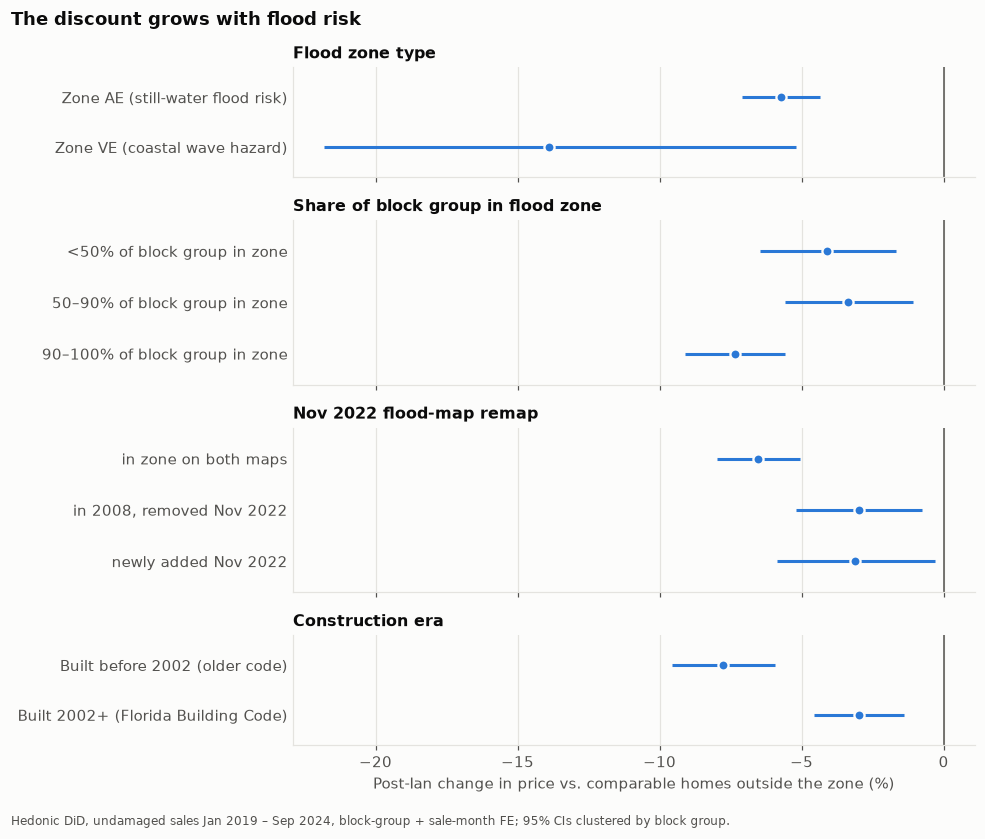

In [9]:
groups = [
    ("Flood zone type", ["Zone AE (still-water flood risk)", "Zone VE (coastal wave hazard)"]),
    ("Share of block group in flood zone", [k for k in mechs.index if k.startswith("Flood-zone home in")]),
    ("Nov 2022 flood-map remap", ["Remap: in zone on both maps", "Remap: in 2008, removed Nov 2022", "Remap: newly added Nov 2022"]),
    ("Construction era", ["Built before 2002 (older code)", "Built 2002+ (Florida Building Code)"]),
]
fig, axes = plt.subplots(len(groups), 1, figsize=(9, 7.4), sharex=True,
                         gridspec_kw={"height_ratios": [len(g[1]) for g in groups]})
for ax, (title, rows) in zip(axes, groups):
    p = mechs.loc[rows].iloc[::-1]
    y = np.arange(len(p))
    ax.hlines(y, p["lo_pct"], p["hi_pct"], color=C1, lw=2)
    ax.scatter(p["premium_pct"], y, color=C1, s=44, zorder=3, edgecolor=SURFACE, lw=1.5)
    ax.set_yticks(y, [r.split(": ", 1)[-1] if r.startswith("Remap") else r.replace("Flood-zone home in a block group ", "").replace(" flood zone", " of block group in zone") for r in p.index])
    ax.tick_params(axis="y", length=0); ax.axvline(0, color=INK2, lw=1)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(title, fontsize=10.5); ax.set_ylim(-0.6, len(p) - 0.4)
axes[-1].set_xlabel("Post-Ian change in price vs. comparable homes outside the zone (%)")
fig.suptitle("The discount grows with flood risk", x=0.01, ha="left", fontweight="bold", fontsize=12, color=INK)
source_note(fig, "Hedonic DiD, undamaged sales Jan 2019 – Sep 2024, block-group + sale-month FE; 95% CIs clustered by block group.")
save(fig, FIG / "04_mechanisms.png")

**Read:**
- **Dose-response by hazard:** homes in **VE** zones, the coastal strip exposed to storm *waves*, lost about
  **14%** relative value: more than double the AE-zone effect. Few VE homes sell, hence the wide interval.
- **Dose-response by neighborhood:** flood-zone homes in block groups that are almost entirely flood zone
  (deep coastal and canal areas) lost about **7%**; those in mixed areas, near the zone edge, about 3–4%.
- **Remap:** homes **removed** from the high-risk zone in the Nov 2022 remap lost value too, about as much as
  homes **newly added**. Both lost less than homes in the zone on both maps. The label alone doesn't explain
  the discount: buyers responded to underlying exposure, which the old and new maps partly disagree on.
- **Building code era:** flood-zone homes built **before 2002** lost about **8%**; those built under the
  2002 Florida Building Code (adopted after Hurricane Andrew) lost about **3%**, less than half as much. The difference
  is statistically clear. Newer homes also tend to be built at higher elevation under modern flood rules, so
  this mixes construction quality with elevation, which the data can't separate. Either way, buyers priced
  in resilience.
- **Helene/Milton (2024)** added no measurable second discount on top of Ian's.

Together these point to **risk repricing**: buyers paying less for exposure they'd just seen realized, and
less still for older, more vulnerable construction. That fits better than a pure insurance-mandate effect or a
general "waterfront fell out of favor" story.

## 5. The damaged-sales question

Phase 3 found that homes sold storm-damaged are coded differently (`qual_cd 03`) and were initially dropped.
How much does including them change the answer, and what's the discount on a damaged sale?

In [10]:
r_all, _ = D.did(D.main_sample(d, damaged=True))
post = D.main_sample(d, damaged=True)
post = post[post["post"] == 1].assign(dmg=lambda x: x["damaged_sale"].astype(float))
r_dmg, _ = D.estimate(post, ["dmg"], extra=["dmg"], controls=[c for c in D.CONTROLS])
pd.DataFrame({
    "flood-zone DiD, undamaged only": main.iloc[0],
    "flood-zone DiD, including damaged": r_all.iloc[0],
    "price of a damaged vs. comparable undamaged sale (post-Ian)": r_dmg.iloc[0],
}).T[["premium_pct", "lo_pct", "hi_pct", "n"]].round(1)

,premium_pct,lo_pct,hi_pct,n
"flood-zone DiD, undamaged only",-5.8,-7.2,-4.5,83327.0
"flood-zone DiD, including damaged",-8.2,-9.8,-6.6,85974.0
price of a damaged vs. comparable undamaged sale (post-Ian),-8.3,-9.8,-6.7,24124.0


Including damaged sales deepens the flood-zone effect by ~2–3 points: **survivor bias was real**. The direct
discount on a damaged sale is smaller than one might guess, likely because the tax-roll record describes the
home *before* the storm, many damaged homes are valued mostly for their land, and buyers of damaged homes in
desirable flood-zone locations are often rebuilders paying for the lot.

## 6. Scale: what does ~6% mean county-wide?

A back-of-envelope estimate of the market value lost by single-family homes in the 2008 flood zone. Inputs:
every single-family parcel in the county GIS layer, its location on the 2008 map, and its appraised value
converted to market value with the recent sale-to-appraisal ratio.

In [11]:
import pyogrio, geopandas as gpd
import build_sales as bs
gdb = next(bs.RAW.glob("lee_gis/parcels/**/*.gdb"))
pts = gpd.read_file(gdb, layer="ParcelPointsData", columns=["STRAP", "DORCODE", "JUST"]).rename(columns={"STRAP": "parcel_id"})
pts = pts[pts["DORCODE"] == "01"].to_crs(bs.CRS)
fz = bs.flood_zones(pts)
stock = pts.drop(columns="geometry").join(fz, on="parcel_id")
ratio = (d.loc[(d["sale_yr"] == 2024) & (d["just_value"] > 0), "sale_price"] / d.loc[(d["sale_yr"] == 2024) & (d["just_value"] > 0), "just_value"]).median()
fz_stock = stock[stock["sfha_2008"] & (stock["JUST"] > 0)]
e = main.iloc[0]
loss = lambda value, pct: value * (-pct / 100) / (1 + pct / 100)   # vs. the no-Ian counterfactual
value_weighted = fz_stock["JUST"].sum() * ratio                   # total market value of the stock
typical = len(fz_stock) * fz_stock["JUST"].median() * ratio       # as if every home were the median home
print(f"Single-family homes in the 2008 flood zone: {len(fz_stock):,}")
print(f"Market value, total (appraised × {ratio:.2f}): ${value_weighted/1e9:,.1f}B;  "
      f"median home ≈ ${fz_stock['JUST'].median()*ratio:,.0f}")
for name, v in [("median-home basis", typical), ("value-weighted basis", value_weighted)]:
    print(f"Implied value lost, {name:20s}: ${loss(v, e.premium_pct)/1e9:,.1f}B "
          f"(95% CI ${loss(v, e.hi_pct)/1e9:,.1f}B – ${loss(v, e.lo_pct)/1e9:,.1f}B)")

Single-family homes in the 2008 flood zone: 88,007
Market value, total (appraised × 1.21): $67.2B;  median home ≈ $519,517
Implied value lost, median-home basis   : $2.8B (95% CI $2.1B – $3.5B)
Implied value lost, value-weighted basis: $4.2B (95% CI $3.1B – $5.2B)


A ~6% risk repricing across Lee County's ~88,000 flood-zone homes is on the order of **$3–4 billion** of
housing wealth. The low end treats every home as the median home. The high end applies 6% to total value,
which is dominated by expensive Gulf and island homes. This is a rough scale, not a precise number: it assumes
the average effect applies to every home, uses one county-wide appraisal ratio, and counts only single-family
homes (not condos or commercial property). It also measures *relative* value: the flood-zone discount compared with what those homes
would be worth had the pre-Ian gap held.

## 7. Conclusions

1. **Yes, Ian lowered flood-zone home values.** Single-family homes in the high-risk zone sold for **~6% less**
   than comparable homes outside it after the storm (main estimate −5.8%, robust range about −2% to −8%,
   repeat-sales −4.4%). The placebo test finds nothing.
2. **The drop was immediate and partly persistent:** about −8% in the first six months, settling to roughly
   −2.5 to −4.5% through Sept 2024. Helene and Milton added no measurable second discount.
3. **It scales with risk:** ~14% in VE coastal wave zones, ~7% deep inside the flood zone, ~3–4% near its edge.
4. **Newer construction held value:** post-2002 building-code homes lost ~3% vs. ~8% for older homes.
5. **It's risk, not just the label:** homes removed from the map in Nov 2022 lost value too.
6. **Survivor bias matters:** including storm-damaged sales deepens the effect by ~2–3 points.
7. **Scale:** on the order of **$3–4 billion** of single-family housing wealth.

**Limitations.**
- No storm-surge inundation or elevation data, so "flood zone" stands in for actual exposure.
- No insurance-cost data, so the Risk Rating 2.0 explanation for the pre-storm fade is a hypothesis.
- Sale dates are month-only.
- Amenities come from a 2024 snapshot.
- Homes aren't randomly assigned to flood zones. The design assumes their *relative* trend would have
  continued, which the pre-period supports only approximately (section 2).

**Next, Part 3:** the same tools applied to condominiums, where Ian coincided with a major change in Florida
condo law.